# Deep Q-Learning (DQN) with PyTorch and Gymnasium

*Notebook 3 of the series: value functions → Q-learning → **DQN***

This notebook builds the DQN algorithm (Mnih et al., 2015, *"Human-level control through deep reinforcement learning"*)
step by step. It follows the structure of CleanRL's single-file implementation
[`dqn_atari.py`](https://github.com/vwxyzjn/cleanrl/blob/master/cleanrl/dqn_atari.py), with every piece explained.

## From a Q-table to a Q-network

In notebook 2, Q-learning stored one number per (state, action) pair. That breaks down when states are images.
An Atari screen has more possible configurations than any table could hold, and the agent never sees the same
screen twice. So we replace the table with a neural network $Q_\theta(s, a)$ that **generalizes** between similar states.

The update becomes a regression problem. Minimize

$$\mathcal{L}(\theta) = \mathbb{E}_{(s,a,r,s') \sim \mathcal{D}} \Big[ \big( \underbrace{r + \gamma\, (1 - \text{done}) \max_{a'} Q_{\theta^-}(s', a')}_{\text{TD target (no gradient)}} - Q_\theta(s, a) \big)^2 \Big]$$

This is exactly the semi-gradient idea from the value network in notebook 1. On its own, though, it is unstable.
DQN adds **two fixes**:

| Problem | Fix |
|---|---|
| Consecutive frames are highly **correlated**, and SGD assumes independent samples. The network also forgets old experience. | **Experience replay** $\mathcal{D}$: store transitions in a large buffer and train on random mini-batches. |
| The target $r + \gamma \max Q_\theta(s')$ moves every time $\theta$ changes, so we are **chasing our own tail**. | **Target network** $Q_{\theta^-}$: a frozen copy of the network that computes targets and is synced only every *C* steps. |

## Roadmap
1. The building blocks: hyperparameters, Q-network, replay buffer, ε schedule.
2. The training loop, line by line, as in CleanRL.
3. **Part A, CartPole:** trains in a few minutes on a CPU, so you can watch DQN actually learn.
4. **Part B, Atari Breakout:** the full CleanRL setup with all the Atari preprocessing wrappers.

In [1]:
# !pip install "gymnasium[atari]" ale-py torch matplotlib  optuna plotly   # uncomment if needed
import random
import time
from collections import defaultdict
from dataclasses import dataclass, replace

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("gymnasium", gym.__version__, "| torch", torch.__version__, "| device:", device)

gymnasium 1.4.0 | torch 2.14.1 | device: cpu


## 1. Hyperparameters

The same `Args` dataclass as CleanRL. The defaults are CleanRL's Atari settings. CleanRL reads these from the
command line with `tyro`; in a notebook we simply create an `Args(...)` object.

In [2]:
@dataclass
class Args:
    env_id: str = "BreakoutNoFrameskip-v4"
    seed: int = 1
    total_timesteps: int = 10_000_000   # agent steps (each one is 4 game frames on Atari)
    learning_rate: float = 1e-4
    buffer_size: int = 1_000_000        # replay memory size
    gamma: float = 0.99                 # discount factor
    tau: float = 1.0                    # target update rate (1.0 = hard copy)
    target_network_frequency: int = 1000  # steps between target-network updates
    batch_size: int = 32
    start_e: float = 1.0                # epsilon at the start...
    end_e: float = 0.01                 # ...decays linearly to this
    exploration_fraction: float = 0.10  # ...over this fraction of total_timesteps
    learning_starts: int = 80_000       # collect this many random steps before learning
    train_frequency: int = 4            # one gradient step every 4 env steps
    optimize_memory_usage: bool = True  # replay-buffer trick (see section 3)

Args()

Args(env_id='BreakoutNoFrameskip-v4', seed=1, total_timesteps=10000000, learning_rate=0.0001, buffer_size=1000000, gamma=0.99, tau=1.0, target_network_frequency=1000, batch_size=32, start_e=1.0, end_e=0.01, exploration_fraction=0.1, learning_starts=80000, train_frequency=4, optimize_memory_usage=True)

## 2. The Q-network

The network takes a state and outputs **one Q-value per action**, all in a single forward pass.
Acting greedily is then just `argmax` over that output.

For Atari this is the "Nature CNN" from the DQN paper. The input is a stack of 4 grayscale 84×84 frames,
so the network can see motion (a single frame can't tell you which way the ball is moving):

| Layer | Output shape |
|---|---|
| input (4 stacked frames) | 4 × 84 × 84 |
| Conv 32 filters, 8×8, stride 4 + ReLU | 32 × 20 × 20 |
| Conv 64 filters, 4×4, stride 2 + ReLU | 64 × 9 × 9 |
| Conv 64 filters, 3×3, stride 1 + ReLU | 64 × 7 × 7 = **3136** |
| Linear 512 + ReLU | 512 |
| Linear → Q-value per action | n_actions |

For CartPole the state is just 4 numbers, so a small MLP is enough.

In [4]:
class QNetwork(nn.Module):
    '''Nature-DQN CNN, identical to CleanRL's dqn_atari.py.'''
    def __init__(self, env):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(4, 32, 8, stride=4), nn.ReLU(),
            nn.Conv2d(32, 64, 4, stride=2), nn.ReLU(),
            nn.Conv2d(64, 64, 3, stride=1), nn.ReLU(),
            nn.Flatten(),
            nn.Linear(3136, 512), nn.ReLU(),
            nn.Linear(512, env.action_space.n),
        )

    def forward(self, x):
        return self.network(x / 255.0)          # pixels 0..255 -> 0..1


class MLPQNetwork(nn.Module):
    '''Small MLP for low-dimensional states such as CartPole.'''
    def __init__(self, env):
        super().__init__()
        n_obs = int(np.prod(env.observation_space.shape))
        self.network = nn.Sequential(
            nn.Linear(n_obs, 120), nn.ReLU(),
            nn.Linear(120, 84), nn.ReLU(),
            nn.Linear(84, env.action_space.n),
        )

    def forward(self, x):
        return self.network(x)


# shape check with a fake Atari observation
class _FakeEnv:
    action_space = gym.spaces.Discrete(4)
q = QNetwork(_FakeEnv())
print("Q-values for a batch of 2 Atari states:", q(torch.zeros(2, 4, 84, 84)).shape)
print(f"parameters: {sum(p.numel() for p in q.parameters()):,}")

Q-values for a batch of 2 Atari states: torch.Size([2, 4])
parameters: 1,686,180


## 3. The replay buffer

A circular buffer of transitions $(s, a, r, s', \text{terminated})$. When it is full, the oldest entries are
overwritten. `sample()` returns a **random** mini-batch, which breaks the correlation between consecutive steps.

CleanRL uses Stable-Baselines3's `ReplayBuffer`. Here is a self-contained version with the same behavior.

**Memory trick (`optimize_memory_usage`).** On Atari one observation is 4×84×84 bytes, about 28 KB.
Storing both `obs` and `next_obs` for 1M transitions would take about 56 GB. But the `next_obs` of step *t*
is the `obs` of step *t+1*, so we store observations only once and read `next_obs` from the following slot.
- At the end of an episode that slot is later overwritten by the reset observation. That's harmless after a
  real termination, because the target multiplies the next-state value by `(1 - done)`.
- It would be wrong after a *truncation* (time limit). Those are rare on Atari, so we use the trick there but
  not on CartPole, where every successful episode is truncated at 500 steps.

In [5]:
class ReplayBuffer:
    def __init__(self, size, obs_shape, obs_dtype, device, optimize_memory_usage=False):
        self.size, self.device, self.optimize = size, device, optimize_memory_usage
        self.obs = np.zeros((size, *obs_shape), dtype=obs_dtype)
        self.next_obs = None if optimize_memory_usage else np.zeros((size, *obs_shape), dtype=obs_dtype)
        self.actions = np.zeros((size, 1), dtype=np.int64)
        self.rewards = np.zeros(size, dtype=np.float32)
        self.dones = np.zeros(size, dtype=np.float32)
        self.pos, self.full = 0, False

    def add(self, obs, next_obs, action, reward, terminated):
        self.obs[self.pos] = obs
        if self.optimize:
            self.obs[(self.pos + 1) % self.size] = next_obs     # next_obs lives in the next slot
        else:
            self.next_obs[self.pos] = next_obs
        self.actions[self.pos] = action
        self.rewards[self.pos] = reward
        self.dones[self.pos] = terminated                     # only TRUE terminations stop bootstrapping
        self.pos = (self.pos + 1) % self.size
        self.full = self.full or self.pos == 0

    def __len__(self):
        return self.size if self.full else self.pos

    def sample(self, batch_size):
        if self.optimize and self.full:
            # skip slot `pos`: its obs was just overwritten by the newest next_obs
            idx = (np.random.randint(1, self.size, size=batch_size) + self.pos) % self.size
        else:
            idx = np.random.randint(0, len(self), size=batch_size)
        next_obs = self.obs[(idx + 1) % self.size] if self.optimize else self.next_obs[idx]
        t = lambda x: torch.as_tensor(x, device=self.device)
        return (t(self.obs[idx]).float(), t(self.actions[idx]), t(next_obs).float(),
                t(self.rewards[idx]), t(self.dones[idx]))

## 4. Exploration schedule

ε decays **linearly** from `start_e` to `end_e` over the first `exploration_fraction` of training and then
stays there. At the start the network is random, so acting on it is pointless and the agent explores fully.

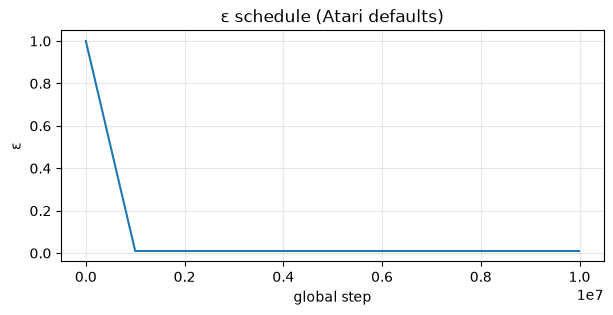

In [6]:
def linear_schedule(start_e: float, end_e: float, duration: int, t: int):
    slope = (end_e - start_e) / duration
    return max(slope * t + start_e, end_e)

a = Args()
steps = np.arange(0, a.total_timesteps, 10_000)
plt.figure(figsize=(7, 3))
plt.plot(steps, [linear_schedule(a.start_e, a.end_e, a.exploration_fraction * a.total_timesteps, t) for t in steps])
plt.xlabel("global step"); plt.ylabel("ε"); plt.title("ε schedule (Atari defaults)"); plt.grid(alpha=.3); plt.show()

## 5. The DQN training loop

This mirrors the main loop of CleanRL's `dqn_atari.py`. Every environment step:

1. **Act** ε-greedily with the online network $Q_\theta$.
2. **Step** the environment and **store** $(s, a, r, s', \text{terminated})$ in the replay buffer.
3. After `learning_starts` steps, every `train_frequency` steps:
   - sample a mini-batch,
   - compute the TD target with the **target network** under `torch.no_grad()`,
   - take a gradient step on the MSE between $Q_\theta(s,a)$ and the target.
4. Every `target_network_frequency` steps, update the target network:
   $\theta^- \leftarrow \tau\,\theta + (1-\tau)\,\theta^-$. With $\tau = 1$ this is a plain copy.

Two notes compared with the original file:
- CleanRL wraps the environment in a `SyncVectorEnv` (with only one env). Vector envs reset automatically, so the
  real final observation is hidden in `infos["final_observation"]`. With a **single** Gymnasium environment,
  `step()` returns the true final observation directly and we call `reset()` ourselves, so no workaround is needed.
- `obs = next_obs`, which CleanRL marks *"CRUCIAL step easy to overlook"*, is still here.

In [7]:
def train_dqn(args, env, QNet, log_interval=50_000, callback=None, callback_interval=10_000):
    random.seed(args.seed); np.random.seed(args.seed); torch.manual_seed(args.seed)

    q_network = QNet(env).to(device)
    optimizer = optim.Adam(q_network.parameters(), lr=args.learning_rate)
    target_network = QNet(env).to(device)
    target_network.load_state_dict(q_network.state_dict())        # start as an exact copy

    rb = ReplayBuffer(args.buffer_size, env.observation_space.shape, env.observation_space.dtype,
                      device, args.optimize_memory_usage)
    log = defaultdict(list)
    start_time = time.time()

    env.action_space.seed(args.seed)
    obs, _ = env.reset(seed=args.seed)
    for global_step in range(args.total_timesteps):
        # 1) act epsilon-greedily
        epsilon = linear_schedule(args.start_e, args.end_e,
                                  args.exploration_fraction * args.total_timesteps, global_step)
        if random.random() < epsilon:
            action = env.action_space.sample()
        else:
            with torch.no_grad():
                q_values = q_network(torch.as_tensor(np.asarray(obs), device=device).float().unsqueeze(0))
            action = int(q_values.argmax(dim=1))

        # 2) step the environment and store the transition
        next_obs, reward, terminated, truncated, info = env.step(action)
        rb.add(obs, next_obs, action, reward, terminated)
        obs = next_obs                                             # CRUCIAL step easy to overlook

        if terminated or truncated:
            if "episode" in info:                                  # a real game ended (RecordEpisodeStatistics)
                log["episode_step"].append(global_step)
                log["episode_return"].append(float(info["episode"]["r"]))
            obs, _ = env.reset()

        # 3) learn
        if global_step > args.learning_starts:
            if global_step % args.train_frequency == 0:
                b_obs, b_actions, b_next_obs, b_rewards, b_dones = rb.sample(args.batch_size)
                with torch.no_grad():                              # targets from the FROZEN network
                    target_max, _ = target_network(b_next_obs).max(dim=1)
                    td_target = b_rewards + args.gamma * target_max * (1 - b_dones)
                old_val = q_network(b_obs).gather(1, b_actions).squeeze(1)   # Q(s, a) for the taken actions
                loss = F.mse_loss(td_target, old_val)

                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

                if global_step % 100 == 0:
                    log["train_step"].append(global_step)
                    log["td_loss"].append(loss.item())
                    log["q_value"].append(old_val.mean().item())

            # 4) update the target network
            if global_step % args.target_network_frequency == 0:
                for target_param, q_param in zip(target_network.parameters(), q_network.parameters()):
                    target_param.data.copy_(args.tau * q_param.data + (1.0 - args.tau) * target_param.data)

        if log_interval and global_step > 0 and global_step % log_interval == 0:
            recent = log["episode_return"][-20:]
            sps = int(global_step / (time.time() - start_time))
            print(f"step {global_step:>8,} | ε={epsilon:.2f} | avg return (last 20) "
                  f"{np.mean(recent) if recent else float('nan'):7.1f} | SPS {sps}")

        # optional hook, used by the Optuna tuner in Part C (report progress / prune)
        if callback is not None and global_step > 0 and global_step % callback_interval == 0:
            callback(global_step, log)

    return q_network, log

`gather(1, actions)` picks, for each row of the batch, the Q-value of the action that was actually taken:

```
q_network(obs)  = [[0.1, 0.7],      actions = [[1],     ->  old_val = [0.7,
                   [0.4, 0.2]]                 [0]]                    0.4]
```

Next come two helpers: one to evaluate a trained agent and one to plot the training logs.

In [8]:
def evaluate(env, q_network, episodes=10, epsilon=0.0, seed=10_000):
    '''Average return of the (almost) greedy policy over full games.'''
    returns, done_games = [], 0
    obs, _ = env.reset(seed=seed)
    while done_games < episodes:
        if random.random() < epsilon:
            action = env.action_space.sample()
        else:
            with torch.no_grad():
                action = int(q_network(torch.as_tensor(np.asarray(obs), device=device).float().unsqueeze(0)).argmax())
        obs, _, terminated, truncated, info = env.step(action)
        if terminated or truncated:
            if "episode" in info:
                returns.append(float(info["episode"]["r"]))
                done_games += 1
            obs, _ = env.reset()
    return np.array(returns)


def plot_training(log, title, window=20):
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    r = np.array(log["episode_return"])
    ax[0].plot(log["episode_step"], r, alpha=0.25, label="episode")
    if len(r) >= window:
        ax[0].plot(log["episode_step"][window - 1:], np.convolve(r, np.ones(window) / window, "valid"),
                   label=f"rolling mean ({window})")
    ax[0].set(title="episodic return", xlabel="global step"); ax[0].legend()
    ax[1].plot(log["train_step"], log["td_loss"]); ax[1].set(title="TD loss", xlabel="global step", yscale="log")
    ax[2].plot(log["train_step"], log["q_value"]); ax[2].set(title="mean Q(s, a) of batch", xlabel="global step")
    fig.suptitle(title); plt.tight_layout(); plt.show()

# Part A: DQN on CartPole

Balance a pole on a cart by pushing left or right. The reward is +1 per step, and episodes are capped at
500 steps, so 500 is a perfect score. The settings below match CleanRL's `dqn.py` (its CartPole version).
This takes roughly 2–4 minutes on a CPU.

step   50,000 | ε=0.81 | avg return (last 20)    30.2 | SPS 34535
step  100,000 | ε=0.62 | avg return (last 20)    73.6 | SPS 30065
step  150,000 | ε=0.43 | avg return (last 20)   167.7 | SPS 28031
step  200,000 | ε=0.24 | avg return (last 20)   309.8 | SPS 26679
step  250,000 | ε=0.05 | avg return (last 20)   500.0 | SPS 25575
step  300,000 | ε=0.05 | avg return (last 20)   467.8 | SPS 24799
step  350,000 | ε=0.05 | avg return (last 20)   444.3 | SPS 24177
step  400,000 | ε=0.05 | avg return (last 20)   495.1 | SPS 23780
step  450,000 | ε=0.05 | avg return (last 20)   500.0 | SPS 23470


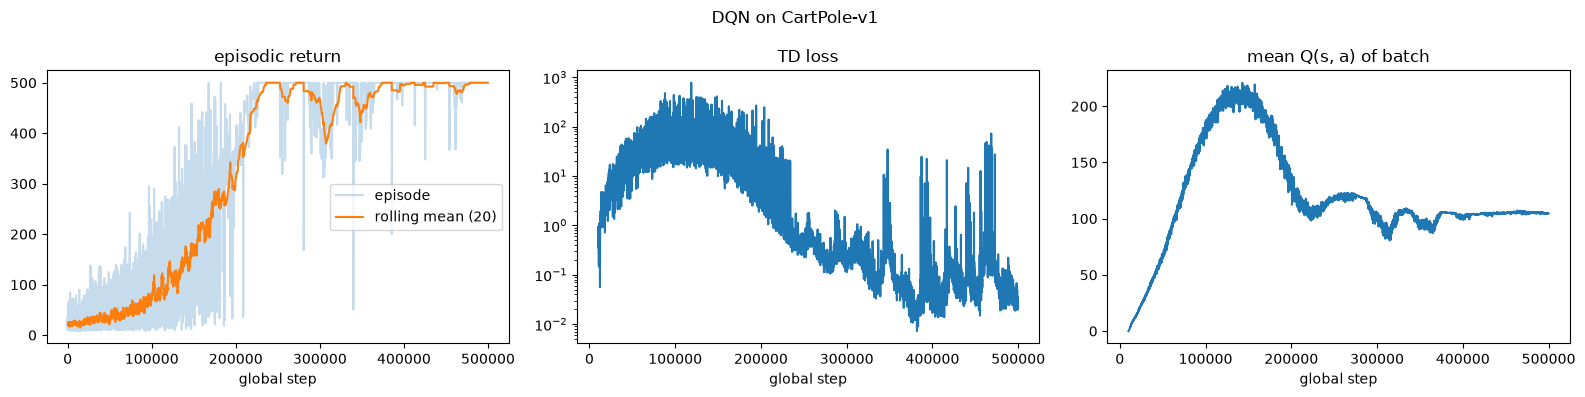

In [9]:
cartpole_args = replace(
    Args(),
    env_id="CartPole-v1",
    total_timesteps=500_000,
    learning_rate=2.5e-4,
    buffer_size=10_000,
    target_network_frequency=500,
    batch_size=128,
    end_e=0.05,
    exploration_fraction=0.5,
    learning_starts=10_000,
    train_frequency=10,
    optimize_memory_usage=False,      # CartPole episodes get truncated, so store next_obs explicitly
)

cp_env = gym.wrappers.RecordEpisodeStatistics(gym.make(cartpole_args.env_id))
cp_q, cp_log = train_dqn(cartpole_args, cp_env, MLPQNetwork)
plot_training(cp_log, "DQN on CartPole-v1")

**Reading the plots**
- **Returns** stay low while ε is high, because the agent is mostly random. They climb as ε decays over the first
  250k steps, then reach the 500 cap and stay there.
- **TD loss** behaves nothing like a supervised loss. It *rises* during learning, because the targets grow as the
  policy improves and every target-network sync shifts them. It only falls once the policy stops changing.
- **Mean Q** is the most instructive plot. With γ = 0.99 and +1 per step, no state can be worth more than
  $\sum_t 0.99^t = 1/(1-0.99) = 100$. Yet the Q-values overshoot to about **215** before settling near 100.
  This is DQN's **overestimation bias**: the `max` in the target always picks whichever action's value is
  currently overestimated, and bootstrapping feeds that error back into itself.
  Here it corrects itself, but in harder environments it can destabilize training.
  Double DQN, at the end of this notebook, was designed to fix exactly this.

In [10]:
cp_eval_env = gym.wrappers.RecordEpisodeStatistics(gym.make("CartPole-v1"))
returns = evaluate(cp_eval_env, cp_q, episodes=20, epsilon=0.0)
print(f"greedy policy over 20 episodes: mean {returns.mean():.1f}, min {returns.min():.0f}, max {returns.max():.0f}")

greedy policy over 20 episodes: mean 500.0, min 500, max 500


# Part B: DQN on Atari (Breakout)

The algorithm is unchanged. What changes is the **input pipeline**. Raw Atari frames are 210×160 RGB at 60 fps,
so DQN uses a stack of preprocessing wrappers, the ones `make_env` applies in CleanRL:

| Wrapper | What it does | Why |
|---|---|---|
| `RecordEpisodeStatistics` | records the raw game score and length | logging the *true* score, before clipping |
| `NoopResetEnv(30)` | 1–30 random no-op actions after reset | random start states, so the agent can't memorize one sequence |
| `MaxAndSkipEnv(4)` | repeat each action 4 frames, max over the last 2 | 4× fewer decisions; max removes Atari sprite flicker |
| `EpisodicLifeEnv` | losing a life counts as `terminated` | the agent learns that losing a life is bad |
| `FireResetEnv` | press FIRE after reset | Breakout does nothing until FIRE launches the ball |
| `ClipRewardEnv` | reward → sign(reward) ∈ {−1, 0, +1} | one learning rate works across games with different scales |
| `ResizeObservation(84,84)` + `GrayscaleObservation` | 210×160×3 → 84×84 | about 20× less input |
| `FrameStackObservation(4)` | stack the last 4 frames | velocity information |

CleanRL imports the first five from `cleanrl_utils.atari_wrappers`, and their implementations follow
Stable-Baselines3's. They are written out below so the notebook is self-contained.
The last three are built into Gymnasium. Note that Gymnasium 1.x renamed `GrayScaleObservation` → `GrayscaleObservation`
and `FrameStack` → `FrameStackObservation`; the CleanRL file still uses the old names.

In [11]:
import ale_py
gym.register_envs(ale_py)          # makes the Atari environments available to gym.make


class NoopResetEnv(gym.Wrapper):
    def __init__(self, env, noop_max=30):
        super().__init__(env)
        self.noop_max = noop_max

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        for _ in range(self.unwrapped.np_random.integers(1, self.noop_max + 1)):
            obs, _, terminated, truncated, info = self.env.step(0)       # 0 = NOOP
            if terminated or truncated:
                obs, info = self.env.reset()
        return obs, info


class MaxAndSkipEnv(gym.Wrapper):
    def __init__(self, env, skip=4):
        super().__init__(env)
        self.skip = skip
        self.frames = np.zeros((2, *env.observation_space.shape), dtype=env.observation_space.dtype)

    def step(self, action):
        total_reward = 0.0
        for i in range(self.skip):
            obs, reward, terminated, truncated, info = self.env.step(action)
            if i >= self.skip - 2:
                self.frames[i - (self.skip - 2)] = obs
            total_reward += reward
            if terminated or truncated:
                break
        return self.frames.max(axis=0), total_reward, terminated, truncated, info


class EpisodicLifeEnv(gym.Wrapper):
    def __init__(self, env):
        super().__init__(env)
        self.lives, self.real_done = 0, True

    def step(self, action):
        obs, reward, terminated, truncated, info = self.env.step(action)
        self.real_done = terminated or truncated
        lives = self.unwrapped.ale.lives()
        if 0 < lives < self.lives:
            terminated = True                     # life lost: end of "episode" for learning
        self.lives = lives
        return obs, reward, terminated, truncated, info

    def reset(self, **kwargs):
        if self.real_done:                        # real game over: actually reset
            obs, info = self.env.reset(**kwargs)
        else:                                     # just a lost life: keep playing
            obs, _, _, _, info = self.env.step(0)
        self.lives = self.unwrapped.ale.lives()
        return obs, info


class FireResetEnv(gym.Wrapper):
    def reset(self, **kwargs):
        self.env.reset(**kwargs)
        obs, _, terminated, truncated, _ = self.env.step(1)              # 1 = FIRE
        if terminated or truncated:
            self.env.reset(**kwargs)
        obs, _, terminated, truncated, info = self.env.step(2)
        if terminated or truncated:
            self.env.reset(**kwargs)
        return obs, info


class ClipRewardEnv(gym.RewardWrapper):
    def reward(self, reward):
        return float(np.sign(reward))


def make_atari_env(env_id, seed):
    env = gym.make(env_id)
    env = gym.wrappers.RecordEpisodeStatistics(env)
    env = NoopResetEnv(env, noop_max=30)
    env = MaxAndSkipEnv(env, skip=4)
    env = EpisodicLifeEnv(env)
    if "FIRE" in env.unwrapped.get_action_meanings():
        env = FireResetEnv(env)
    env = ClipRewardEnv(env)
    env = gym.wrappers.ResizeObservation(env, (84, 84))
    env = gym.wrappers.GrayscaleObservation(env)
    env = gym.wrappers.FrameStackObservation(env, 4)
    env.action_space.seed(seed)
    return env

### What the network actually sees

raw frame: (210, 160, 3) uint8 | processed observation: (4, 84, 84) uint8
actions: ['NOOP', 'FIRE', 'RIGHT', 'LEFT']


A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]


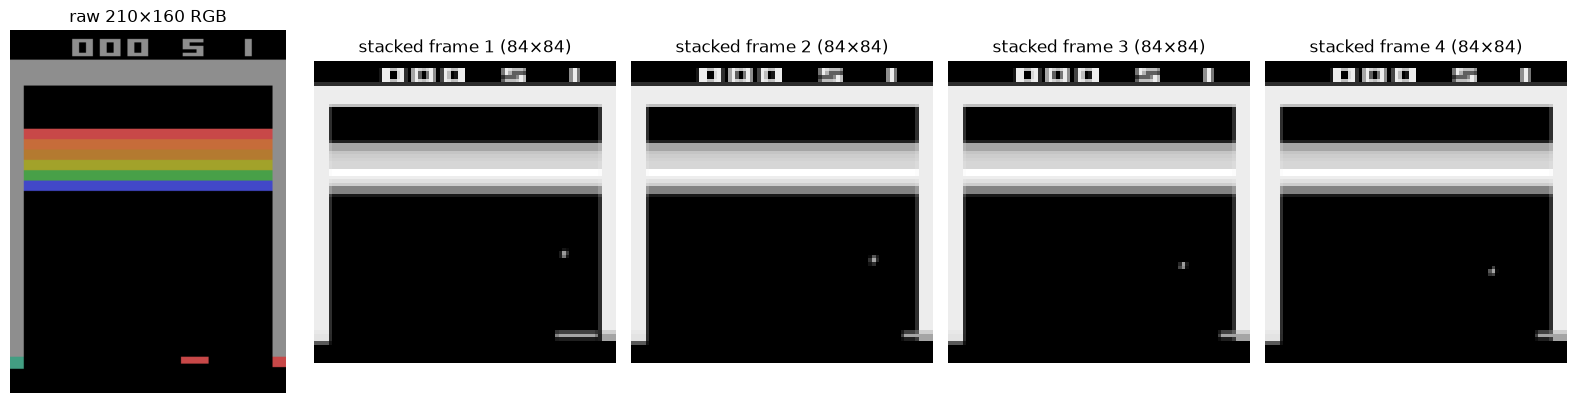

In [12]:
atari_args = Args()                                   # CleanRL's Atari defaults
raw_env = gym.make(atari_args.env_id)
raw_obs, _ = raw_env.reset(seed=0)

env = make_atari_env(atari_args.env_id, atari_args.seed)
obs, _ = env.reset(seed=0)
for a in [2, 2, 2, 3]:                                # move a bit so the frames differ
    obs, *_ = env.step(a)

print("raw frame:", raw_obs.shape, raw_obs.dtype, "| processed observation:", obs.shape, obs.dtype)
print("actions:", env.unwrapped.get_action_meanings())

fig, ax = plt.subplots(1, 5, figsize=(16, 4))
ax[0].imshow(raw_obs); ax[0].set_title("raw 210×160 RGB")
for i in range(4):
    ax[i + 1].imshow(obs[i], cmap="gray"); ax[i + 1].set_title(f"stacked frame {i + 1} (84×84)")
for a_ in ax:
    a_.axis("off")
plt.tight_layout(); plt.show()

### Training

The full CleanRL run is **10 million steps** (40M game frames). On a GPU that takes many hours; on a CPU it
would take days, so it's switched off by default. Memory: even with `optimize_memory_usage`, a 1M-transition
buffer needs about **28 GB of RAM**. On a typical machine or Colab, use `buffer_size=100_000` (about 3 GB).
That learns somewhat worse, but it works.

The cell below always runs a **short smoke test**, a few thousand steps, to check that everything is wired correctly.
Set `RUN_FULL_TRAINING = True` for the real run.

In [13]:
RUN_FULL_TRAINING = False

if RUN_FULL_TRAINING:
    run_args = replace(atari_args, buffer_size=100_000)      # lower than CleanRL's 1M to fit in RAM
    log_interval = 100_000
else:
    run_args = replace(atari_args, total_timesteps=3_000, learning_starts=1_000, buffer_size=3_000)
    log_interval = 1_000

atari_env = make_atari_env(run_args.env_id, run_args.seed)
atari_q, atari_log = train_dqn(run_args, atari_env, QNetwork, log_interval=log_interval)
print(f"\nfinished {run_args.total_timesteps:,} steps | games played: {len(atari_log['episode_return'])} "
      f"| gradient steps logged: {len(atari_log['td_loss'])}")

if RUN_FULL_TRAINING:
    plot_training(atari_log, f"DQN on {run_args.env_id}", window=100)
    torch.save(atari_q.state_dict(), "dqn_breakout.pt")

step    1,000 | ε=0.01 | avg return (last 20)     2.6 | SPS 1318
step    2,000 | ε=0.01 | avg return (last 20)     2.3 | SPS 246

finished 3,000 steps | games played: 16 | gradient steps logged: 19


In [14]:
# Evaluate like CleanRL does: 10 full games with a small epsilon (end_e)
eval_returns = evaluate(make_atari_env(run_args.env_id, seed=123), atari_q, episodes=10 if RUN_FULL_TRAINING else 3,
                        epsilon=run_args.end_e)
print("evaluation returns (raw game score):", eval_returns)

evaluation returns (raw game score): [2. 2. 2.]


After the 3,000-step smoke test these scores are close to random play, which is expected. A real Breakout agent
needs millions of steps. Even then, the learning curve typically stays flat for a long time before scores take off.

# Part C: Hyperparameter tuning with Optuna

DQN is notoriously sensitive to its hyperparameters. The same algorithm can solve CartPole in 30k steps or never
solve it, depending on the learning rate, target-network frequency and exploration schedule. Instead of guessing,
we let [Optuna](https://optuna.org) search for good settings.

### Optuna in four concepts
| Concept | Meaning here |
|---|---|
| **Study** | the whole search, "maximize evaluation return" |
| **Trial** | one DQN training run with one sampled set of hyperparameters |
| **Sampler** (TPE) | proposes the next hyperparameters, based on which earlier trials scored well (Bayesian-style) |
| **Pruner** (Median) | stops a trial early if it is doing worse than the median of earlier trials at the same step, which saves a lot of compute |

### The plan
1. Write an `objective(trial)` that samples hyperparameters, trains DQN for a **fixed, shorter budget**, and returns
   the greedy evaluation score.
2. During training, report progress every 10k steps so bad trials can be **pruned**.
3. Run the study, inspect the results, then **validate** the winner against the defaults on **fresh seeds**.

We tune on CartPole because each trial takes seconds to minutes. Tuning directly on Atari (hours per trial) is
rarely practical; see the notes at the end of this part.

In [16]:
# !pip install optuna        # optional extras: pip install optuna-dashboard plotly
import optuna
from optuna.pruners import MedianPruner
from optuna.samplers import TPESampler

import warnings
warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)   # matplotlib plots are "experimental"
optuna.logging.set_verbosity(optuna.logging.WARNING)       # we print our own one-line summary per trial
print("optuna", optuna.__version__)

optuna 5.0.0


/Users/harvindersingh/miniforge3/envs/rl/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Tuning settings and the search space

`TRIAL_STEPS` is the budget for each trial. It is deliberately **shorter** than the 500k steps of Part A, so the search
favors settings that learn fast. `SEEDS_PER_TRIAL > 1` averages each trial over several seeds. That is slower, but it
is much more robust, because DQN results vary a lot between seeds.

| Hyperparameter | Range | Why it matters |
|---|---|---|
| `learning_rate` | 1e-4 to 3e-3 (log scale) | too high: divergence; too low: slow |
| `batch_size` | 32 – 256 | gradient noise vs compute |
| `buffer_size` | 10k – 100k | sample diversity vs staleness |
| `target_network_frequency` | 100 – 2000 | stability vs speed of propagating values |
| `gamma` | 0.95 – 0.995 | planning horizon |
| `exploration_fraction`, `end_e` | 0.05–0.5, 0.01–0.1 | how long and how much to explore |
| `learning_starts` | 1k – 10k | how much random data before learning |
| `train_frequency` | 1, 4, 10 | gradient steps per env step (1 is the most sample-efficient, and the slowest) |

In [17]:
TRIAL_STEPS = 100_000        # env steps per trial
SEEDS_PER_TRIAL = 1          # raise to 2-3 for more reliable (but slower) tuning
N_TRIALS = 50
TIMEOUT_SECONDS = None       # e.g. 3600 to stop the whole study after one hour
REPORT_EVERY = 10_000        # how often a trial reports progress to the pruner
EVAL_EPISODES = 10

base_args = cartpole_args    # start from the Part A settings and override what we tune


def sample_dqn_params(trial):
    return dict(
        learning_rate=trial.suggest_float("learning_rate", 1e-4, 3e-3, log=True),
        batch_size=trial.suggest_categorical("batch_size", [32, 64, 128, 256]),
        buffer_size=trial.suggest_categorical("buffer_size", [10_000, 50_000, 100_000]),
        target_network_frequency=trial.suggest_categorical("target_network_frequency", [100, 250, 500, 1000, 2000]),
        gamma=trial.suggest_categorical("gamma", [0.95, 0.98, 0.99, 0.995]),
        exploration_fraction=trial.suggest_float("exploration_fraction", 0.05, 0.5),
        end_e=trial.suggest_float("end_e", 0.01, 0.1),
        learning_starts=trial.suggest_categorical("learning_starts", [1_000, 5_000, 10_000]),
        train_frequency=trial.suggest_categorical("train_frequency", [1, 4, 10]),
    )

## 2. The objective function

For each seed, the objective trains, then evaluates greedily and returns the mean score. While training,
the `callback` reports the recent training return to Optuna every `REPORT_EVERY` steps. If the pruner decides
the trial is hopeless, `raise optuna.TrialPruned()` aborts `train_dqn` right there.

With several seeds, the reported step is offset per seed (`seed_idx * TRIAL_STEPS + step`). That way every trial
reports at the same positions, and the pruner compares like with like.

In [18]:
def objective(trial):
    params = sample_dqn_params(trial)
    scores = []
    t0 = time.time()
    for seed_idx in range(SEEDS_PER_TRIAL):
        args = replace(base_args, total_timesteps=TRIAL_STEPS, seed=1000 + seed_idx, **params)

        def report(step, log, offset=seed_idx * TRIAL_STEPS):
            recent = log["episode_return"][-10:]
            trial.report(float(np.mean(recent)) if recent else 0.0, offset + step)
            if trial.should_prune():
                print(f"trial {trial.number:>3} pruned at step {offset + step:,}  ({time.time() - t0:.0f}s)")
                raise optuna.TrialPruned()

        env = gym.wrappers.RecordEpisodeStatistics(gym.make(args.env_id))
        q_net, _ = train_dqn(args, env, MLPQNetwork, log_interval=0,
                             callback=report, callback_interval=REPORT_EVERY)

        eval_env = gym.wrappers.RecordEpisodeStatistics(gym.make(args.env_id))
        scores.append(evaluate(eval_env, q_net, episodes=EVAL_EPISODES, epsilon=0.0, seed=50_000 + seed_idx).mean())

    score = float(np.mean(scores))
    print(f"trial {trial.number:>3} finished: score {score:6.1f}  ({time.time() - t0:.0f}s)")
    return score

## 3. Run the study

- `TPESampler(seed=...)` makes the *sequence of suggestions* reproducible. Training itself is seeded inside the objective.
- `MedianPruner(n_startup_trials=5, n_warmup_steps=30_000)`: never prune during the first 5 trials, which build up a
  baseline, or before step 30k of any trial, because early DQN returns say very little.
- To **resume** a study later, or watch it live with `optuna-dashboard sqlite:///dqn_optuna.db`, pass
  `storage="sqlite:///dqn_optuna.db", load_if_exists=True`.

Expect roughly 15–60 minutes on a CPU with the defaults above, depending on how much gets pruned and how often
`train_frequency=1` is sampled. Reduce `N_TRIALS` or `TRIAL_STEPS` for a quicker run.

In [19]:
study = optuna.create_study(
    study_name="dqn_cartpole",
    direction="maximize",
    sampler=TPESampler(seed=42),
    pruner=MedianPruner(n_startup_trials=5, n_warmup_steps=30_000),
    # storage="sqlite:///dqn_optuna.db", load_if_exists=True,
)

# Optional: queue the Part A settings as the first trial, so the baseline is part of the search
TUNED = ["learning_rate", "batch_size", "buffer_size", "target_network_frequency", "gamma",
         "exploration_fraction", "end_e", "learning_starts", "train_frequency"]
study.enqueue_trial({k: getattr(base_args, k) for k in TUNED})

start = time.time()
study.optimize(objective, n_trials=N_TRIALS, timeout=TIMEOUT_SECONDS)
print(f"\nstudy finished in {(time.time() - start) / 60:.1f} min")

trial   0 finished: score  337.6  (5s)
trial   1 finished: score  326.4  (4s)
trial   2 finished: score  140.3  (9s)
trial   3 finished: score  101.3  (8s)
trial   4 finished: score  491.8  (25s)
trial   5 pruned at step 30,000  (7s)
trial   6 finished: score  306.8  (23s)
trial   7 finished: score  500.0  (5s)
trial   8 pruned at step 30,000  (6s)
trial   9 pruned at step 30,000  (2s)
trial  10 pruned at step 30,000  (1s)
trial  11 pruned at step 30,000  (1s)
trial  12 pruned at step 70,000  (4s)
trial  13 pruned at step 30,000  (7s)
trial  14 pruned at step 30,000  (8s)
trial  15 pruned at step 30,000  (7s)
trial  16 pruned at step 90,000  (22s)
trial  17 pruned at step 70,000  (3s)
trial  18 pruned at step 30,000  (1s)
trial  19 pruned at step 30,000  (1s)
trial  20 finished: score  223.7  (5s)
trial  21 pruned at step 30,000  (1s)
trial  22 pruned at step 30,000  (1s)
trial  23 pruned at step 30,000  (1s)
trial  24 pruned at step 30,000  (8s)
trial  25 pruned at step 80,000  (3s)
t

## 4. Results

In [22]:
states = [t.state for t in study.trials]
print(f"trials: {len(states)} | complete: {states.count(optuna.trial.TrialState.COMPLETE)} "
      f"| pruned: {states.count(optuna.trial.TrialState.PRUNED)}")
print(f"\nbest score: {study.best_value:.1f}  (trial {study.best_trial.number})")
print("best hyperparameters:")
for k, v in study.best_params.items():
    print(f"   {k:<26} {v}")

# top 10 completed trials as a table
df = study.trials_dataframe(attrs=("number", "value", "params", "state"))
df = df[df["state"] == "COMPLETE"].sort_values("value", ascending=False)
df.columns = [c.replace("params_", "") for c in df.columns]
df.head(10)

trials: 50 | complete: 12 | pruned: 38

best score: 500.0  (trial 7)
best hyperparameters:
   learning_rate              0.0021959317857485673
   batch_size                 256
   buffer_size                100000
   target_network_frequency   250
   gamma                      0.99
   exploration_fraction       0.1339333296799344
   end_e                      0.013669762739928754
   learning_starts            5000
   train_frequency            10


,number,value,batch_size,buffer_size,end_e,exploration_fraction,gamma,learning_rate,learning_starts,target_network_frequency,train_frequency,state
7,7,500.0,256,100000,0.013670,0.133933,0.990,0.002196,5000,250,10,COMPLETE
45,45,500.0,256,100000,0.018224,0.175599,0.990,0.002058,5000,250,10,COMPLETE
48,48,500.0,256,100000,0.053283,0.256257,0.990,0.001356,5000,250,10,COMPLETE
30,30,498.2,256,100000,0.049159,0.168146,0.990,0.001521,5000,250,10,COMPLETE
4,4,491.8,32,10000,0.060515,0.392353,0.950,0.001194,1000,1000,1,COMPLETE
36,36,437.2,256,100000,0.052891,0.186737,0.990,0.001851,5000,250,10,COMPLETE
0,0,337.6,128,10000,0.050000,0.500000,0.990,0.000250,10000,500,10,COMPLETE
1,1,326.4,32,100000,0.048875,0.286140,0.995,0.000357,5000,1000,10,COMPLETE
6,6,306.8,64,10000,0.037079,0.273762,0.980,0.000427,10000,250,1,COMPLETE
20,20,223.7,256,100000,0.023303,0.152568,0.950,0.001335,5000,250,10,COMPLETE


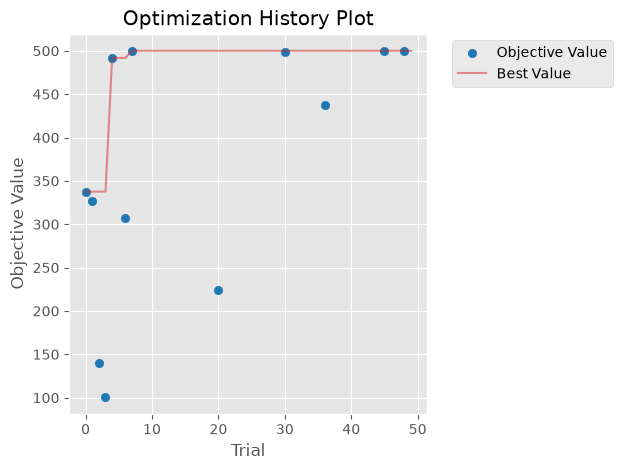

/Users/harvindersingh/miniforge3/envs/rl/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.canvas.print_figure(bytes_io, **kw)


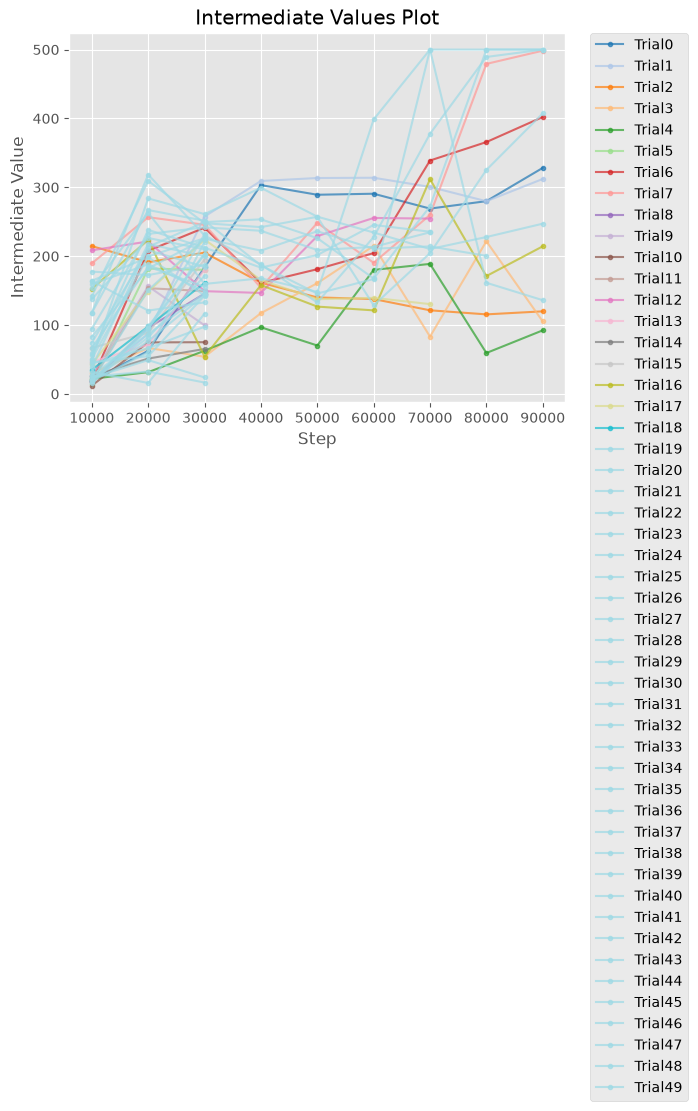

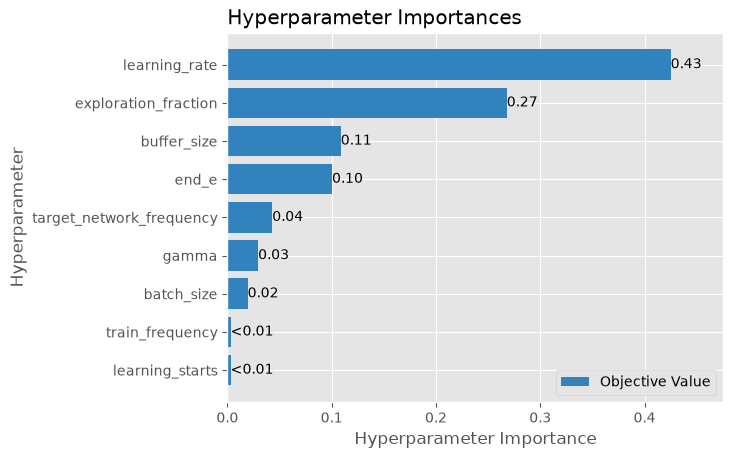

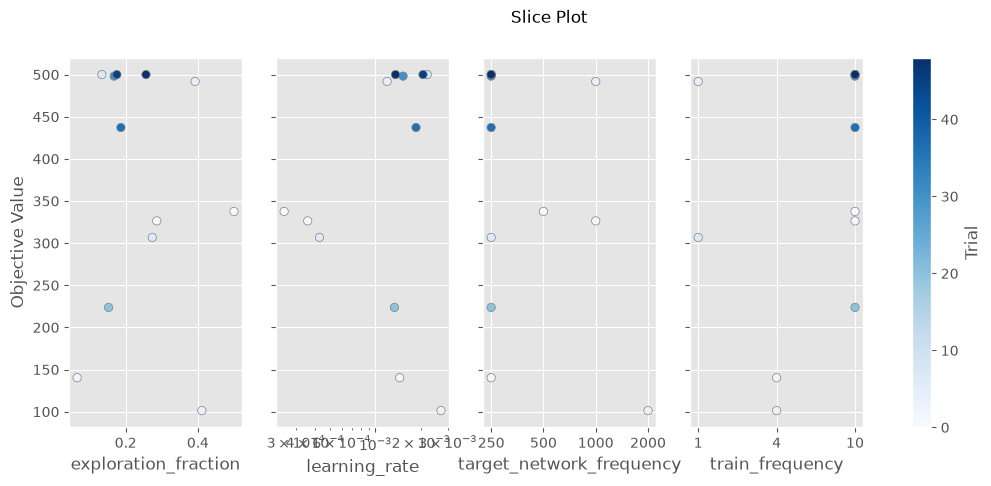

In [23]:
from optuna.visualization.matplotlib import (plot_optimization_history, plot_param_importances,
                                             plot_slice, plot_intermediate_values)

plot_optimization_history(study); plt.show()      # score per trial + best so far
plot_intermediate_values(study); plt.show()       # the learning curves the pruner saw (pruned ones stop early)

completed = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
if len(completed) >= 5:
    plot_param_importances(study); plt.show()     # which hyperparameters mattered most (fANOVA)
    plot_slice(study, params=["learning_rate", "target_network_frequency",
                              "exploration_fraction", "train_frequency"]); plt.show()

# Interactive versions (need plotly): optuna.visualization.plot_optimization_history(study).show(), etc.

## 5. Validate the winner on fresh seeds

The best trial's score is **optimistically biased**. It is the maximum over many noisy runs, and it was measured
on the tuning seeds. The honest test is to retrain the best configuration and the baseline on **seeds never used
during tuning**, with the same budget, and compare.

Part A defaults  eval per seed: [315.9 334.6 279. ]  -> mean 309.8
Optuna best      eval per seed: [500.  363.6 500. ]  -> mean 454.6


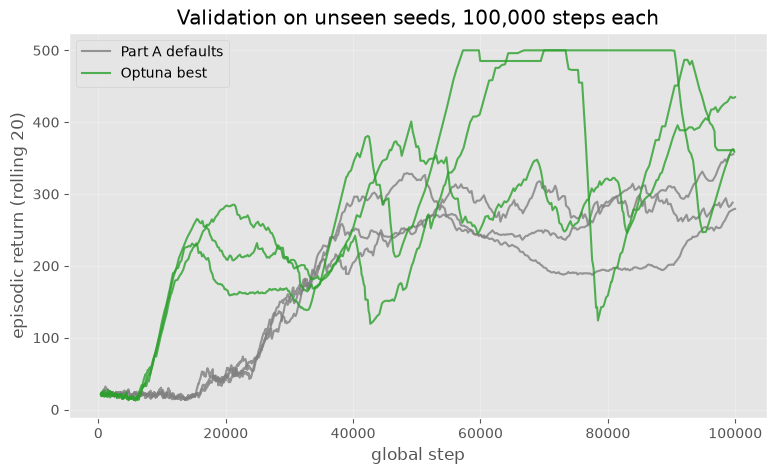

In [24]:
VALIDATION_SEEDS = [7, 8, 9]

def run_config(params, seed, steps=TRIAL_STEPS):
    args = replace(base_args, total_timesteps=steps, seed=seed, **params)
    env = gym.wrappers.RecordEpisodeStatistics(gym.make(args.env_id))
    q_net, log = train_dqn(args, env, MLPQNetwork, log_interval=0)
    eval_env = gym.wrappers.RecordEpisodeStatistics(gym.make(args.env_id))
    return evaluate(eval_env, q_net, episodes=20, epsilon=0.0, seed=90_000 + seed).mean(), log

configs = {"Part A defaults": {}, "Optuna best": study.best_params}
results = {}
fig, ax = plt.subplots(figsize=(9, 5))
for (name, params), color in zip(configs.items(), ["tab:gray", "tab:green"]):
    results[name] = []
    for i, seed in enumerate(VALIDATION_SEEDS):
        score, log = run_config(params, seed)
        results[name].append(score)
        r = np.array(log["episode_return"])
        if len(r) >= 20:
            ax.plot(log["episode_step"][19:], np.convolve(r, np.ones(20) / 20, "valid"),
                    color=color, alpha=0.8, label=name if i == 0 else None)
    print(f"{name:<16} eval per seed: {np.round(results[name], 1)}  -> mean {np.mean(results[name]):.1f}")

ax.set(xlabel="global step", ylabel="episodic return (rolling 20)",
       title=f"Validation on unseen seeds, {TRIAL_STEPS:,} steps each")
ax.legend(); ax.grid(alpha=.3); plt.show()

## Tuning pitfalls (especially in RL)

- **Seed overfitting.** With `SEEDS_PER_TRIAL = 1`, a lucky configuration can win by chance. Always validate on new
  seeds (section 5), and use 2–3 seeds per trial once you trust the setup.
- **Budget mismatch.** Settings tuned for 100k steps favor *fast* learning (high learning rate, short exploration),
  which can be unstable over longer runs. Tune with the budget you will actually train with, or validate longer.
- **The metric shapes the result.** Here: greedy evaluation at the end. Alternatives include the area under the
  learning curve (rewards learning fast) or the mean of the last N training episodes (rewards a stable finish).
- **Atari.** Each trial costs hours. Common strategies: tune on a few cheaper games or with a shorter budget, then
  transfer the settings. CleanRL's own tuner (`cleanrl_utils/tuner.py`, built on Optuna) scores trials on
  *several* environments with normalized returns for exactly this reason. Or use Population Based Training,
  which tunes *during* a single training run.



DQN = **Q-learning** + **a neural network** + **experience replay** + **a target network**.

- The loss is a regression onto $r + \gamma(1-\text{done})\max_{a'} Q_{\theta^-}(s',a')$, with no gradient through the target.
- Replay breaks the correlation between samples and reuses experience. The target network keeps the regression
  target still for `target_network_frequency` steps.
- Only *true* terminations stop bootstrapping. Truncations should bootstrap.
- DQN is very sensitive to hyperparameters: tune them (Part C), and always validate on unseen seeds.

## Next steps

**Double DQN** (van Hasselt et al., 2016). The `max` in the target picks actions whose Q-values happen to be
overestimated, so DQN is systematically **optimistic**. The fix is to choose the action with the online network
and evaluate it with the target network. It is a two-line change in `train_dqn`:

```python
with torch.no_grad():
    best_actions = q_network(b_next_obs).argmax(dim=1, keepdim=True)            # online net CHOOSES
    target_q = target_network(b_next_obs).gather(1, best_actions).squeeze(1)   # target net EVALUATES
    td_target = b_rewards + args.gamma * target_q * (1 - b_dones)
```

**Further ideas to try**
- **Ablations on CartPole:** set `target_network_frequency=1` (effectively no target network) or `buffer_size=batch_size`
  (effectively no replay) and watch training become unstable.
- **Huber loss:** `F.smooth_l1_loss` instead of MSE, as in the original paper, is more robust to large TD errors.
- **Other improvements:** dueling networks, prioritized replay and n-step returns. Combined with Double DQN they form
  **Rainbow**. CleanRL also has `c51_atari.py` (distributional RL) and `qdagger_dqn_atari_impalacnn.py`.